In [11]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [12]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG16, ResNet50
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import image_dataset_from_directory
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
import random
from PIL import Image
from itertools import cycle
import itertools
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.applications import ResNet50


In [13]:
BASE_DIR = Path("/content/drive/MyDrive/dataset/classification_task")


In [14]:
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = image_dataset_from_directory(
    BASE_DIR / "train",
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=True
)

val_ds = image_dataset_from_directory(
    BASE_DIR / "test",
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)




class_names = train_ds.class_names
print("Classes:", class_names)

Found 5000 files belonging to 4 classes.
Found 1000 files belonging to 4 classes.
Classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary']


In [15]:
count_val = {cls: 0 for cls in class_names}

for images, labels in val_ds:
    batch_labels = np.argmax(labels.numpy(), axis=1)
    for l in batch_labels:
        count_val[class_names[l]] += 1

print("Validation distribution:", count_val)


Validation distribution: {'glioma': 254, 'meningioma': 306, 'no_tumor': 140, 'pituitary': 300}


In [16]:
data_augmentation = tf.keras.Sequential([ layers.RandomFlip("horizontal"), layers.RandomRotation(0.05), layers.RandomZoom(0.1), ])

In [17]:
#def preprocess(image, label):
    #image = tf.cast(image, tf.float32) / 255.0
 #   image = tf.cast(image, tf.float32) / 255.0

   # return image, label
def preprocess(image, label):
    image = tf.cast(image, tf.float32)
    image = vgg_preprocess(image)   # ✅ correct for VGG16
    return image, label



train_ds = train_ds.map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
val_ds = val_ds.map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)

train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
val_ds   = val_ds.prefetch(tf.data.AUTOTUNE)


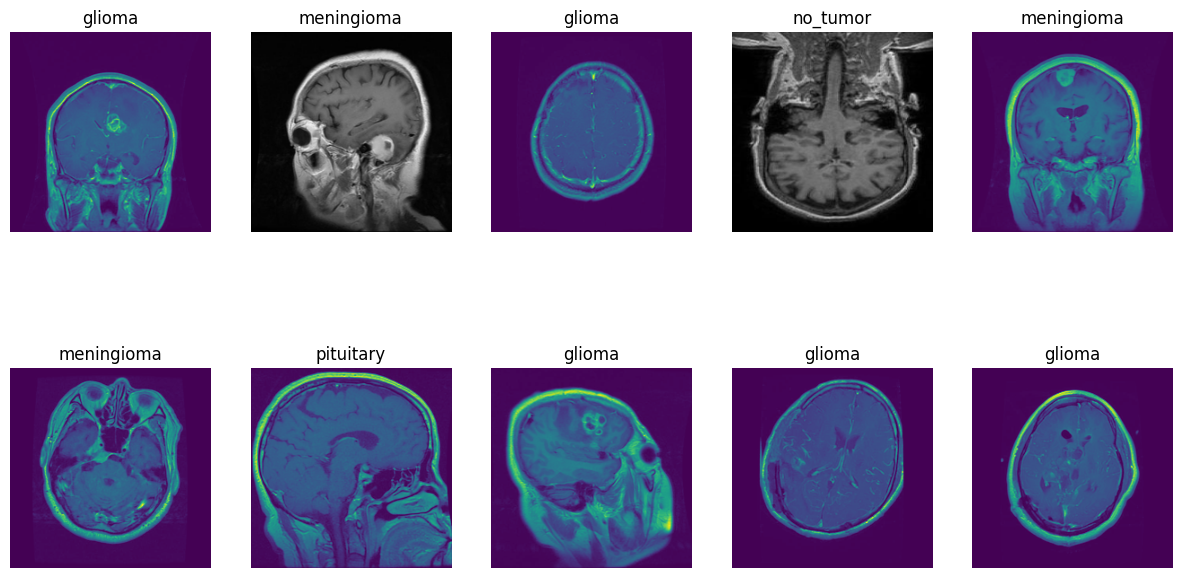

In [18]:
train_paths = list((BASE_DIR/"train").rglob("*.jpg"))
sample_paths = random.sample(train_paths, 10)

plt.figure(figsize=(15, 8))
for i, p in enumerate(sample_paths):
    plt.subplot(2, 5, i+1)
    plt.imshow(Image.open(p).resize((224, 224)))
    plt.title(p.parent.name)
    plt.axis("off")
plt.show()

In [19]:
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_preprocess

def build_vgg16():
    base_model = VGG16(include_top=False, weights="imagenet", input_shape=(224,224,3))
    base_model.trainable = False

    inputs = layers.Input(shape=(224,224,3))
    x = data_augmentation(inputs)
    #x = vgg_preprocess(x)
    x = base_model(x, training=False)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.5)(x)

    outputs = layers.Dense(len(class_names), activation="softmax")(x)

    model = models.Model(inputs, outputs)
    model.compile(optimizer=Adam(3e-4),
                  loss="categorical_crossentropy",
                  metrics=["accuracy"])

    return model

model = build_vgg16()
model.summary()


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,849,092 (56.64 MB)

 Trainable params: 133,380 (521.02 KB)

 Non-trainable params: 14,715,712 (56.14 MB)

In [20]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.3,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stop, reduce_lr]
)


Epoch 1/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 783s 5s/step - accuracy: 0.5654 - loss: 1.1414 - val_accuracy: 0.7520 - val_loss: 0.6491 - learning_rate: 3.0000e-04
Epoch 2/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 33s 211ms/step - accuracy: 0.8128 - loss: 0.5039 - val_accuracy: 0.8150 - val_loss: 0.4822 - learning_rate: 3.0000e-04
Epoch 3/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 34s 219ms/step - accuracy: 0.8618 - loss: 0.3880 - val_accuracy: 0.8440 - val_loss: 0.4117 - learning_rate: 3.0000e-04
Epoch 4/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 33s 211ms/step - accuracy: 0.8737 - loss: 0.3395 - val_accuracy: 0.8700 - val_loss: 0.3504 - learning_rate: 3.0000e-04
Epoch 5/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 40s 208ms/step - accuracy: 0.8825 - loss: 0.3138 - val_accuracy: 0.8750 - val_loss: 0.3280 - learning_rate: 3.0000e-04
Epoch 6/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 33s 207ms/step - accuracy: 0.8903 - loss: 0.2853 - val_accuracy: 0.8810 - val_loss: 0.3065 - learning_rate: 3.0000e-04
Epoch 7/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 34s 215m

In [21]:
model.layers[3].trainable = True  # unfreeze VGG16
#model.get_layer("vgg16").trainable = True


model.compile(optimizer=Adam(1e-6),
              loss="categorical_crossentropy",
              metrics=["accuracy"])

history_ft = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[early_stop, reduce_lr]
)


Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 36s 217ms/step - accuracy: 0.9425 - loss: 0.1588 - val_accuracy: 0.9240 - val_loss: 0.2133 - learning_rate: 1.0000e-06
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 33s 206ms/step - accuracy: 0.9389 - loss: 0.1670 - val_accuracy: 0.9220 - val_loss: 0.2131 - learning_rate: 1.0000e-06
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 34s 214ms/step - accuracy: 0.9477 - loss: 0.1567 - val_accuracy: 0.9230 - val_loss: 0.2121 - learning_rate: 1.0000e-06
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 33s 208ms/step - accuracy: 0.9435 - loss: 0.1579 - val_accuracy: 0.9210 - val_loss: 0.2128 - learning_rate: 1.0000e-06
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 33s 207ms/step - accuracy: 0.9468 - loss: 0.1446 - val_accuracy: 0.9240 - val_loss: 0.2125 - learning_rate: 1.0000e-06


In [22]:
#model.save(f"{"/content/drive/MyDrive/Dataset"}/vgg16.keras")

# ================= SAVE VGG16 MODEL =================
model.save(f"{"/content/drive/MyDrive/dataset"}/vgg16.keras")
print("✅ VGG16 model saved")

# Save class labels
import json
with open(f"{"/content/drive/MyDrive/dataset"}/class_names.json", "w") as f:
    json.dump(class_names, f)

print("✅ Class labels saved")



✅ VGG16 model saved
✅ Class labels saved


In [23]:
def build_resnet50():
    base_model = ResNet50(include_top=False, weights="imagenet", input_shape=(224,224,3))
    base_model.trainable = False

    inputs = layers.Input(shape=(224,224,3))
    x = data_augmentation(inputs)
    x = resnet_preprocess(x)

    x = base_model(x, training=False)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.5)(x)

    outputs = layers.Dense(len(class_names), activation="softmax")(x)

    model = models.Model(inputs, outputs)
    model.compile(
        optimizer=Adam(3e-4),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

resnet_model = build_resnet50()
resnet_model.summary()


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 224, 224,  │          0 │ input_layer_4[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ sequential[1][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ sequential[1][0]  │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ sequential[1][0]  │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ add[0][0]         │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 2048)      │      8,192 │ global_average_p… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 256)       │    524,544 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 256)       │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 4)         │      1,028 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 24,121,476 (92.02 MB)

 Trainable params: 529,668 (2.02 MB)

 Non-trainable params: 23,591,808 (90.00 MB)

In [24]:

history_resnet = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stop, reduce_lr]
)


Epoch 1/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 45s 235ms/step - accuracy: 0.6530 - loss: 0.9721 - val_accuracy: 0.8570 - val_loss: 0.4094 - learning_rate: 3.0000e-04
Epoch 2/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 34s 214ms/step - accuracy: 0.8607 - loss: 0.4003 - val_accuracy: 0.8800 - val_loss: 0.3189 - learning_rate: 3.0000e-04
Epoch 3/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 34s 215ms/step - accuracy: 0.8838 - loss: 0.3092 - val_accuracy: 0.8940 - val_loss: 0.2981 - learning_rate: 3.0000e-04
Epoch 4/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 33s 210ms/step - accuracy: 0.9048 - loss: 0.2687 - val_accuracy: 0.8970 - val_loss: 0.2940 - learning_rate: 3.0000e-04
Epoch 5/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 34s 219ms/step - accuracy: 0.9260 - loss: 0.2062 - val_accuracy: 0.9050 - val_loss: 0.2818 - learning_rate: 3.0000e-04
Epoch 6/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 33s 208ms/step - accuracy: 0.9258 - loss: 0.2164 - val_accuracy: 0.8960 - val_loss: 0.2782 - learning_rate: 3.0000e-04
Epoch 7/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 41s 20

In [25]:
resnet_model.layers[3].trainable = True   # unfreeze top residual block

resnet_model.compile(
    optimizer=Adam(1e-6),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history_resnet_ft = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[early_stop, reduce_lr]
)


Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 43s 231ms/step - accuracy: 0.9429 - loss: 0.1485 - val_accuracy: 0.9180 - val_loss: 0.2373 - learning_rate: 1.0000e-06
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 37s 235ms/step - accuracy: 0.9501 - loss: 0.1315 - val_accuracy: 0.9190 - val_loss: 0.2367 - learning_rate: 1.0000e-06
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 36s 222ms/step - accuracy: 0.9417 - loss: 0.1499 - val_accuracy: 0.9190 - val_loss: 0.2376 - learning_rate: 1.0000e-06
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 34s 213ms/step - accuracy: 0.9539 - loss: 0.1295 - val_accuracy: 0.9190 - val_loss: 0.2350 - learning_rate: 1.0000e-06
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 33s 209ms/step - accuracy: 0.9494 - loss: 0.1396 - val_accuracy: 0.9220 - val_loss: 0.2336 - learning_rate: 1.0000e-06


In [26]:
# ================= SAVE RESNET MODEL =================
resnet_model.save(f"{"/content/drive/MyDrive/dataset"}/resnet50.keras")
print("✅ ResNet50 model saved")


✅ ResNet50 model saved


In [27]:
from tensorflow.keras.models import load_model
import json

# Load models
vgg_loaded = load_model(f"{"/content/drive/MyDrive/dataset"}/vgg16.keras")
resnet_loaded = load_model(f"{"/content/drive/MyDrive/dataset"}/resnet50.keras")

# Load class names
with open(f"{"/content/drive/MyDrive/dataset"}/class_names.json") as f:
    class_names = json.load(f)

# Validate reload
loss, acc = vgg_loaded.evaluate(val_ds)
print(f"Reloaded VGG16 Accuracy: {acc:.4f}")


32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 195ms/step - accuracy: 0.8925 - loss: 0.3024
Reloaded VGG16 Accuracy: 0.9230


In [28]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize

# -----------------------------------------------------------
# FUNCTION 1 — CLASSIFICATION REPORT + PREDICTIONS
# -----------------------------------------------------------
def evaluate_model(model, dataset, class_names):
    y_true = []
    y_pred = []
    y_score = []

    for images, labels in dataset:
        preds = model.predict(images)
        y_pred.extend(np.argmax(preds, axis=1))
        y_true.extend(np.argmax(labels.numpy(), axis=1))
        y_score.extend(preds)

    print("\n===== CLASSIFICATION REPORT =====")
    print(classification_report(y_true, y_pred, target_names=class_names))

    cm = confusion_matrix(y_true, y_pred)
    return np.array(y_true), np.array(y_pred), np.array(y_score), cm

# -----------------------------------------------------------
# FUNCTION 2 — CONFUSION MATRIX
# -----------------------------------------------------------
def plot_confusion(cm, class_names, title):
    plt.figure(figsize=(6,5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

# -----------------------------------------------------------
# FUNCTION 3 — MULTI-CLASS ROC CURVE
# -----------------------------------------------------------
def plot_multi_class_roc(y_true, y_score, class_names):
    n_classes = len(class_names)

    y_true_bin = tf.keras.utils.to_categorical(y_true, num_classes=n_classes)

    plt.figure(figsize=(8,6))
    for i in range(n_classes):
        fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_score[:, i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f"{class_names[i]} (AUC={roc_auc:.2f})")

    plt.plot([0,1], [0,1], 'k--')
    plt.title("Multi-Class ROC Curve")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()
    plt.grid()
    plt.show()




================ VGG16 Evaluation ================

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 660ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 183ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 187ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 192ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 186ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 189ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 197ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 165ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 189ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 174ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step
1/1 ━━━━━━

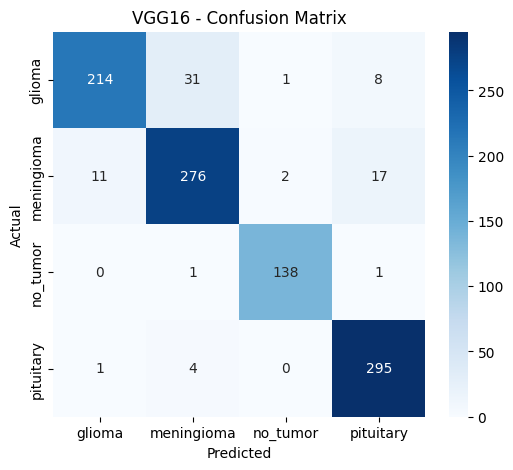

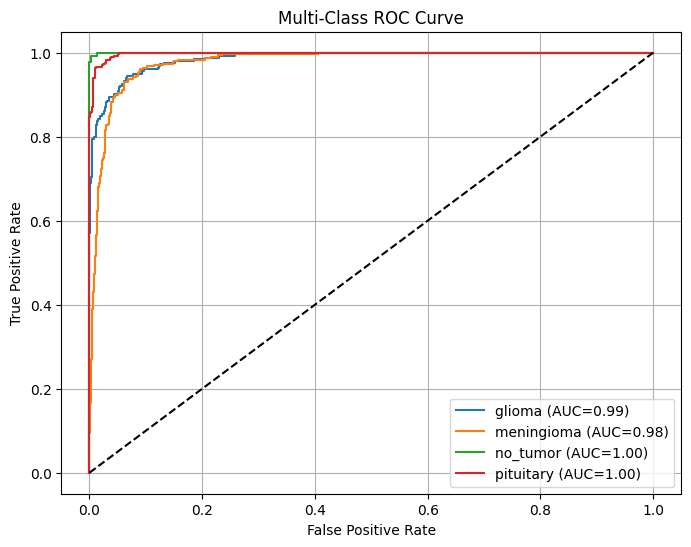

In [29]:
print("\n\n================ VGG16 Evaluation ================\n")
y_true_vgg, y_pred_vgg, y_score_vgg, cm_vgg = evaluate_model(model, val_ds, class_names)

plot_confusion(cm_vgg, class_names, "VGG16 - Confusion Matrix")
plot_multi_class_roc(y_true_vgg, y_score_vgg, class_names)




================ ResNet50 Evaluation ================

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 191ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 165ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 169ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 188ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 190ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 183ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 164ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 192ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 169ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 187ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 196ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 187ms/step
1/1 ━━━━━━

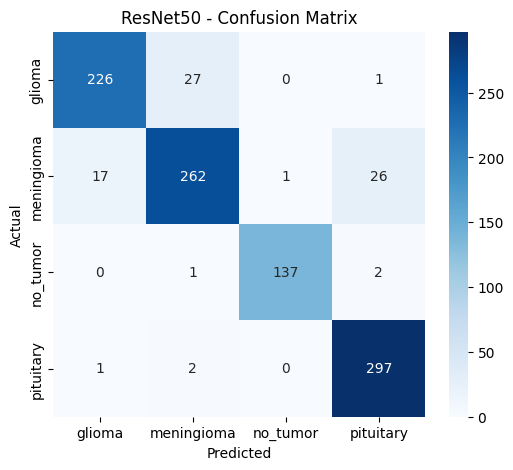

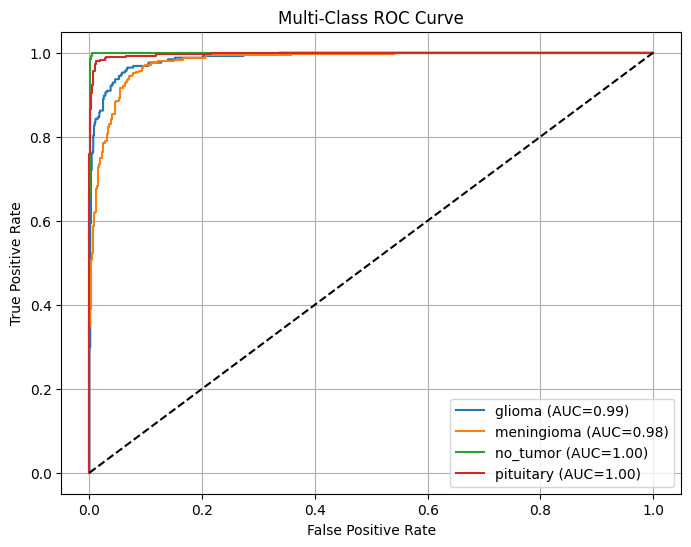

In [30]:
print("\n\n================ ResNet50 Evaluation ================\n")
y_true_resnet, y_pred_resnet, y_score_resnet, cm_resnet = evaluate_model(resnet_model, val_ds, class_names)

plot_confusion(cm_resnet, class_names, "ResNet50 - Confusion Matrix")
plot_multi_class_roc(y_true_resnet, y_score_resnet, class_names)


In [31]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

#def predict_image(model, img_path, class_names):
    # Load and preprocess image
 #   img = Image.open(img_path).resize((224, 224))
  #  img_array = np.array(img).astype("float32") / 255.0
   # img_array = np.expand_dims(img_array, axis=0)

    # Make prediction
  #  predictions = model.predict(img_array)
   # predicted_class = class_names[np.argmax(predictions)]

    # Display image with prediction
  #  plt.imshow(img)
  #  plt.title(f"Predicted: {predicted_class}")
   # plt.axis("off")
    #plt.show()

    #print("Predicted Class:", predicted_class)
    #print("Probabilities:", predictions)
    #return predicted_class

def predict_image(model, img_path, class_names):
    img = Image.open(img_path).resize((224, 224))
    img_array = np.array(img).astype("float32")
    img_array = np.expand_dims(img_array, axis=0)
    img_array = vgg_preprocess(img_array)   # 🔥 match training

    preds = model.predict(img_array)
    idx = np.argmax(preds)

    plt.imshow(img)
    plt.title(f"Predicted: {class_names[idx]}")
    plt.axis("off")
    plt.show()

    return class_names[idx], preds



In [34]:
test_image_path = "/content/drive/MyDrive/dataset/classification_task/test/glioma/brisc2025_test_00013_gl_ax_t1.jpg"


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 616ms/step


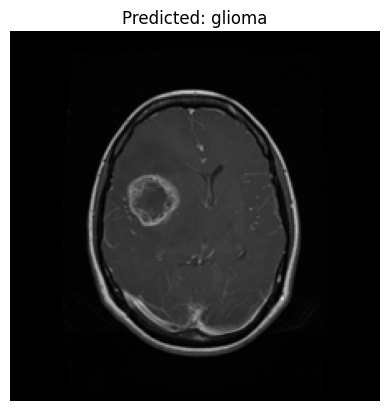

('glioma',
 array([[9.9997568e-01, 2.4216541e-05, 6.2379556e-08, 1.6730155e-08]],
       dtype=float32))

In [35]:
predict_image(model, test_image_path, class_names)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 433ms/step


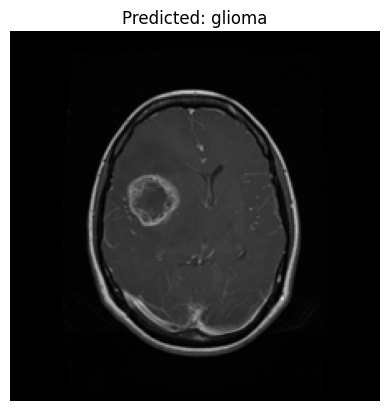

('glioma',
 array([[9.9999857e-01, 9.6085580e-07, 1.9486335e-07, 2.7276479e-07]],
       dtype=float32))

In [36]:
predict_image(resnet_model, test_image_path, class_names)
